![Original climate-globe illustration introducing Association is a question, not a mechanism; illustrative, not a data map](assets/atlas-splash.png)

# 27 · Association is a question, not a mechanism

**Guiding question:** How does a shared trend change an apparent ENSO relationship?

**Data:** Real C3S/ECMWF ERA5 Climate Pulse CSV snapshots retrieved 2026-11-20; CC BY 4.0  
**Time:** 20–35 minutes · **Prerequisites:** basic Python; run cells from top to bottom.  
**Author:** JupyterLite-C3S-Atlas contributors (AI assisted) · **Created/updated:** 2026-11-20  
**Inputs:** bundled reference files and/or seeded examples specified below. **Outputs:** tables, figures, and any explicitly named local exports; source data are not modified.  
**Runtime:** Python/Pyodide; NumPy, pandas, Matplotlib, Plotly; versions and tests are recorded in the validation report.  
**Change log:** initial educational chapter. **Contact:** [repository issues](https://github.com/jltobias/JupyterLite-C3S-Atlas/issues).

[Open in JupyterLite Lab](https://jltobias.github.io/JupyterLite-C3S-Atlas/lite/lab/index.html?path=27-enso-and-global-context.ipynb) · [Official Atlas](https://atlas.climate.copernicus.eu/)


## Read the evidence

Join series by date before comparing them. Global air temperature and a
        Pacific SST index have different spatial and physical meanings. They can co-vary
        because of ENSO, background warming, other processes, and sampling choices.
        A scatterplot alone cannot isolate a cause or forecast an individual place.

        Compare a raw association with a simple linear-detrended sensitivity check over
        a fixed window. Detrending is an assumption, not a causal adjustment. A lag scan
        creates many opportunities to find a peak, and serial dependence makes nominal
        independent-sample significance misleading. Here we report descriptive correlations
        only. The official teleconnection resources show why regional and seasonal outcomes
        must be examined separately.

## Start the browser lab

Run this setup cell once. First load needs internet for the Python runtime and packages. The remaining lesson uses bundled data. If a 3D view is unavailable, use the 2D/table alternative. Download your edited notebook before clearing browser storage.

In [1]:
# Install only in the browser kernel; desktop dependencies come from requirements.txt.
import sys
if sys.platform == "emscripten":
    import piplite
    await piplite.install(["numpy", "pandas", "matplotlib", "plotly==6.5.0"])

import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from IPython.display import display
from atlas_helpers import (
    DATA, SYNTHETIC, COLORS, show, monthly_demo, anomalies, regular_grid,
    area_mean, coastlines, map_figure, globe_figure, warming_levels, load_monthly_csv,
)
print("Ready. Browser edits live in this browser; download work you want to keep.")


Ready. Browser edits live in this browser; download work you want to keep.


## Align quantities with different spatial support

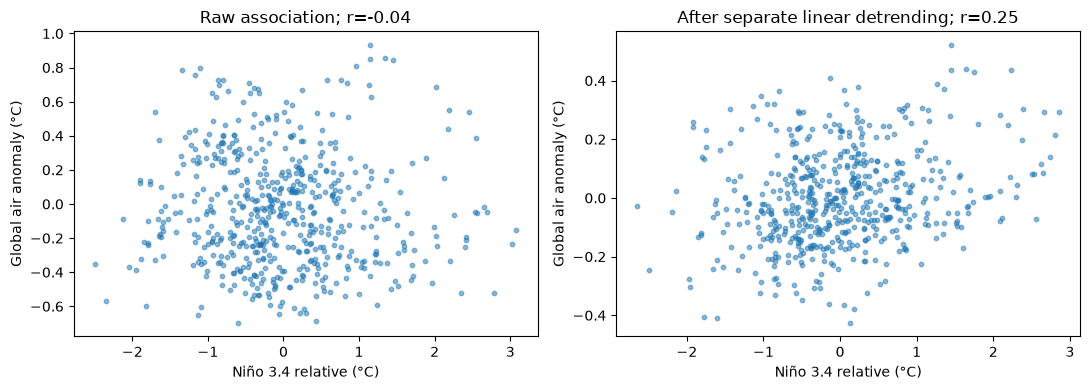

In [2]:
from pulse_helpers import (
    load_pulse, complete_months, rank_same_month, region_rings, region_geojson,
    region_map, region_globe, REGIONS, ANOM, REL, CREDIT, BASE,
)
nino = load_pulse()[["date", REL]].rename(columns={REL: "relative_nino34"})
air = load_pulse("global", variable="t2m")[["date", ANOM]].rename(columns={ANOM: "global_air"})
paired = nino.merge(air, on="date", validate="one_to_one")
paired = paired[(paired.date >= "1979-01-01") & (paired.date <= "2025-12-01")].copy()
assert len(paired) == 47*12
t = np.arange(len(paired))
for col in ["relative_nino34", "global_air"]:
    paired[col+"_detrended"] = paired[col] - np.polyval(np.polyfit(t, paired[col], 1), t)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, suffix, title in zip(axes, ["", "_detrended"], ["Raw association", "After separate linear detrending"]):
    x, y = paired["relative_nino34"+suffix], paired["global_air"+suffix]
    ax.scatter(x, y, s=10, alpha=.5)
    ax.set(title=f"{title}; r={x.corr(y):.2f}", xlabel="Niño 3.4 relative (°C)", ylabel="Global air anomaly (°C)")
plt.tight_layout(); plt.show()

## Inspect lag sensitivity without selecting a forecast

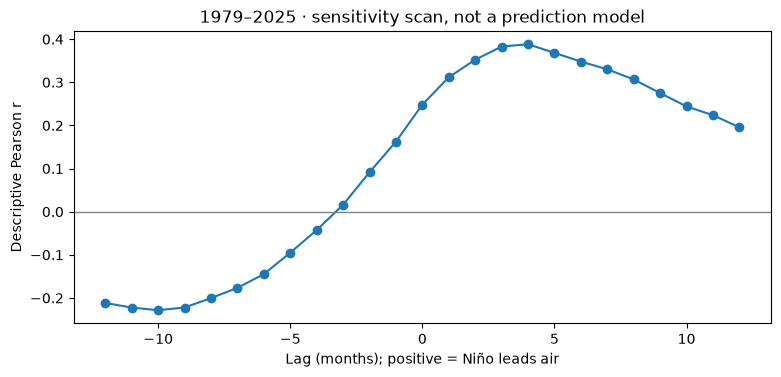

,lag_months,r,pairs
0,-12,-0.211680,552
4,-8,-0.200337,556
8,-4,-0.042600,560
12,0,0.248358,564
16,4,0.388365,560
20,8,0.306555,556
24,12,0.195641,552


In [3]:
rows = []
for lag in range(-12, 13):
    # Positive lag pairs earlier Niño values with later global-air values.
    x = paired.relative_nino34_detrended.shift(lag)
    valid = x.notna() & paired.global_air_detrended.notna()
    rows.append({"lag_months": lag, "r": x[valid].corr(paired.global_air_detrended[valid]), "pairs": int(valid.sum())})
lags = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(lags.lag_months, lags.r, "o-"); ax.axhline(0, color="gray", lw=1)
ax.set(xlabel="Lag (months); positive = Niño leads air", ylabel="Descriptive Pearson r", title="1979–2025 · sensitivity scan, not a prediction model")
plt.show(); display(lags.iloc[::4])

## Try it and explain

Change the analysis window to 1991–2020. Record how the association changes before examining the official regional composites.

**Interpretation check:** A correlation depends on the sample, transformation, and lag. It does not identify the portion of a regional hazard caused by ENSO.

## Transfer to the official tools

Explore the official ENSO impacts page: compare early- and late-winter composites and individual years. Connect a composite to an Atlas variable without treating it as a local forecast.

Record the selections, source version, units, periods, and uncertainty legend. These independent lessons do not duplicate every production workflow in the official tools.

## Sources and credit

- [C3S Atlas dataset and DOI](https://doi.org/10.24381/cds.h35hb680)
- [CSIC / Predictia Atlas user guide](https://confluence.ecmwf.int/spaces/CKB/pages/394237545/Copernicus+Interactive+Climate+Atlas+User+Guide)
- [Official C3S Atlas User Tools and contributors](https://ecmwf-projects.github.io/c3s-atlas/)
- [C3S Climate Pulse 2.0 announcement (10 November 2026)](https://climate.copernicus.eu/new-version-climate-pulse-provides-new-monitoring-el-nino-conditions)
- [Climate Pulse FAQs and methodology](https://pulse.climate.copernicus.eu/faqs)
- [Climate Pulse credits and citations](https://pulse.climate.copernicus.eu/credits)
- [ERA5 monthly data: C3S/ECMWF and ERA5 contributors](https://doi.org/10.24381/cds.f17050d7)
- [Hersbach et al. (2020): The ERA5 global reanalysis](https://doi.org/10.1002/qj.3803)
- [ECMWF ENSO impacts and diversity of regional outcomes](https://confluence.ecmwf.int/spaces/CKB/pages/373753799/ENSO+impacts+based+on+ERA5+reanalysis)

Original teaching text and code; original AI-generated splash illustration. Real reference files retain their source licences. Synthetic examples are not Copernicus measurements. See [credits](credits.md) and [data guide](data-guide.md).

**Continue:** [From Python to RustGIS and GeoLibre](28-rustgis-geolibre.ipynb)